# Clasificación en PyTorch: de tensores y autograd a `torch.nn`


## Objetivos

1. Generar un problema de clasificación binaria.
2. Entrenar un modelo con parámetros creados manualmente.
3. Entender `requires_grad`, `backward()` y `torch.no_grad()`.
4. Reescribir el entrenamiento usando `torch.nn`.
5. Crear un `nn.Module` que actúe como capa personalizada.
6. Construir modelos personalizados y compararlos.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import torch.nn.functional as F
print("PyTorch:", torch.__version__)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

PyTorch: 2.14.0+cpu
Device: cpu


## 1. Generación de datos

El problema usa dos características, \(x_1\) y \(x_2\).

Definimos la clase positiva como una región aproximadamente circular/anular utilizando:


$r^2 = x_1^2 + x_2^2$


Esto hace que una frontera puramente lineal sobre \((x_1,x_2)\) no sea suficiente.

Por ello incluiremos explícitamente la transformación:

$
(x_1,x_2)\rightarrow(x_1^2,x_2^2)
$

In [5]:

import math
N=1000
def sample_ring(n, r_min, r_max):
    # sqrt para que la densidad sea uniforme en área, no concentrada en el centro
    r = torch.sqrt(torch.empty(n).uniform_(r_min**2, r_max**2))
    theta = torch.empty(n).uniform_(0, 2 * math.pi)
    return torch.stack([r * torch.cos(theta), r * torch.sin(theta)], dim=1)

def make_rings(N=2000, inner=(1.5, 4.0), outer=(5.5, 8.0), p_inner=0.4):
    n_in = int(N * p_inner)
    n_out = N - n_in

    X_in = sample_ring(n_in, *inner)     # clase 1 (amarillo)
    X_out = sample_ring(n_out, *outer)   # clase 0 (morado)

    X = torch.cat([X_in, X_out], dim=0)
    y = torch.cat([torch.ones(n_in), torch.zeros(n_out)])

    # Barajar
    perm = torch.randperm(N)
    return X[perm], y[perm]

X, y = make_rings(N=N)

print("X:", X.shape)
print("y:", y.shape)
print("Prevalencia clase 1:", y.mean().item())

X: torch.Size([1000, 2])
y: torch.Size([1000])
Prevalencia clase 1: 0.4000000059604645


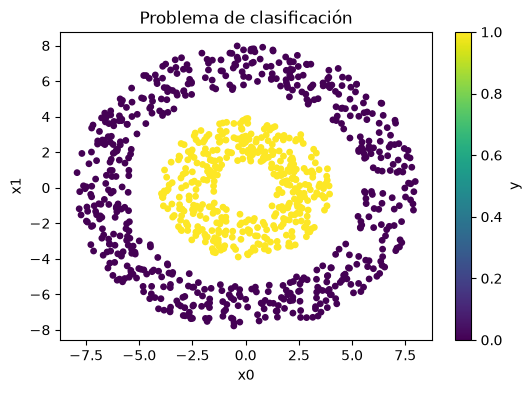

In [6]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    X[:, 0].numpy(),
    X[:, 1].numpy(),
    c=y.numpy(),
    s=15,
    cmap="viridis",
    vmin=0, vmax=1
)
plt.colorbar(sc, label="y")
plt.xlabel("x0")
plt.ylabel("x1")
plt.title("Problema de clasificación")
plt.show()

## 2. `Dataset` y `DataLoader`

`TensorDataset` agrupa tensores que comparten la primera dimensión.

`DataLoader` se encarga de:

- crear batches;
- mezclar los datos;
- iterar por épocas.

In [7]:
dataset = TensorDataset(X, y)

n_train = int(0.8 * N)
n_val = int(0.1 * N)
n_test = N - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)
)

BATCH_SIZE = 64

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE)

print(len(train_set), len(val_set), len(test_set))

800 100 100


# Parte A — PyTorch "manual"

## 3. Crear parámetros directamente

Nuestro clasificador será:

$
z = w_1x_1^2 + w_2x_2^2 + b
$

y convertiremos el logit $z$ en probabilidad con una sigmoide.

Primero crearemos `w` y `b` nosotros mismos, sin `nn.Linear`.

In [8]:
w = torch.randn(2, requires_grad=True, device=device)
b = torch.randn(1, requires_grad=True, device=device)

print("w:", w)
print("b:", b)

w: tensor([-0.8595, -1.2810], requires_grad=True)
b: tensor([-2.0059], requires_grad=True)


## 4. Forward pass manual

In [9]:
def manual_logits(x):
    x2 = x ** 2
    return x2 @ w + b

def manual_probability(x):
    return torch.sigmoid(manual_logits(x))

## 5. Binary cross entropy

En clasificación binaria:

$
-\left[y\log(p)+(1-y)\log(1-p)\right]
$

Para estabilidad numérica es mejor trabajar directamente con los **logits** y usar `binary_cross_entropy_with_logits`.

In [12]:
def binary_loss_from_logits(logits, targets):
    return torch.nn.functional.binary_cross_entropy_with_logits(logits, targets)

## 6. `backward()` y gradient descent manual

Después de `loss.backward()`, PyTorch acumula los gradientes en:

```python
w.grad
b.grad
```

La actualización debe hacerse dentro de `torch.no_grad()` para no agregarla al grafo computacional.

También debemos poner los gradientes nuevamente en cero antes del siguiente paso.

In [13]:
learning_rate = 0.01

def manual_train_step(xb, yb):
    global w, b

    xb = xb.to(device)
    yb = yb.to(device)

    logits = manual_logits(xb)
    loss = binary_loss_from_logits(logits, yb)

    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    w.grad.zero_()
    b.grad.zero_()

    return loss.item()

## 7. Loop de entrenamiento manual

In [17]:
EPOCHS = 120
train_history = []
val_history = []

for epoch in range(EPOCHS):
    batch_losses = []

    for xb, yb in train_loader:
        batch_losses.append(manual_train_step(xb, yb))

    train_loss = np.mean(batch_losses)

    val_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)
            logits = manual_logits(xb)
            val_losses.append(binary_loss_from_logits(logits, yb).item())

    val_loss = np.mean(val_losses)
    train_history.append(train_loss)
    val_history.append(val_loss)

    if epoch % 10 == 0 or epoch == EPOCHS - 1:
        print(
            f"Epoch {epoch+1:3d} | "
            f"train={train_loss:.4f} | val={val_loss:.4f}"
        )

Epoch   1 | train=0.3640 | val=0.3491
Epoch  11 | train=0.3273 | val=0.3198
Epoch  21 | train=0.3043 | val=0.2917
Epoch  31 | train=0.2763 | val=0.2694
Epoch  41 | train=0.2588 | val=0.2494
Epoch  51 | train=0.2382 | val=0.2318
Epoch  61 | train=0.2212 | val=0.2172
Epoch  71 | train=0.2085 | val=0.2033
Epoch  81 | train=0.1936 | val=0.1916
Epoch  91 | train=0.1830 | val=0.1810
Epoch 101 | train=0.1715 | val=0.1716
Epoch 111 | train=0.1637 | val=0.1631
Epoch 120 | train=0.1578 | val=0.1559


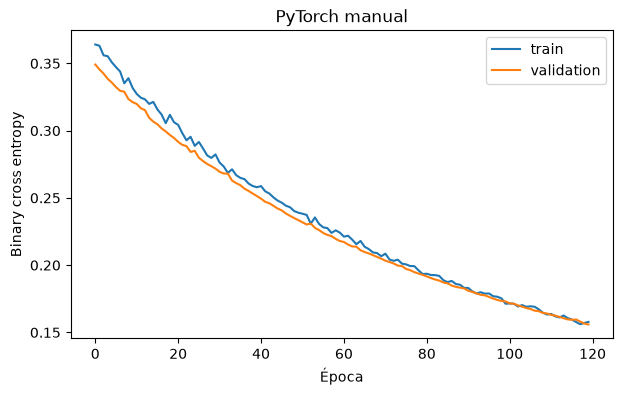

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(train_history, label="train")
plt.plot(val_history, label="validation")
plt.xlabel("Época")
plt.ylabel("Binary cross entropy")
plt.title("PyTorch manual")
plt.legend()
plt.show()

## 8. Evaluación manual

La sigmoide transforma logits en probabilidades. Usamos un threshold de `0.5`.

In [19]:
correct = 0
total = 0

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        probs = manual_probability(xb)
        preds = (probs >= 0.5).float()

        correct += (preds == yb).sum().item()
        total += yb.numel()

print("Test accuracy:", correct / total)
print("w aprendido:", w.detach().cpu().numpy())
print("b aprendido:", b.detach().cpu().numpy())

Test accuracy: 1.0
w aprendido: [-0.11800724 -0.11814996]
b aprendido: [2.181481]


# Parte B — Paso a `torch.nn`

Ahora PyTorch administrará los parámetros dentro de objetos `nn.Module`.

La capa:

```python
nn.Linear(2, 1)
```

representa:

$
z = XW^T + b
$

No añadiremos una `Sigmoid` al modelo porque `BCEWithLogitsLoss` combina de manera numéricamente estable:

- sigmoid;
- binary cross entropy.

In [20]:
class CircleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        x = x ** 2
        logits = self.linear(x)
        return logits.squeeze(1)

model = CircleClassifier().to(device)
print(model)

CircleClassifier(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)


## 9. Loss y optimizer

En PyTorch el patrón habitual es:

```python
optimizer.zero_grad()
logits = model(x)
loss = criterion(logits, y)
loss.backward()
optimizer.step()
```

In [21]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

In [22]:
def evaluate_loss(model, loader):
    model.eval()
    losses = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)
            losses.append(loss.item())

    return np.mean(losses)

## 10. Loop de entrenamiento con `nn.Module`

In [23]:
EPOCHS = 40
train_history_nn = []
val_history_nn = []

for epoch in range(EPOCHS):
    model.train()
    batch_losses = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        batch_losses.append(loss.item())

    train_loss = np.mean(batch_losses)
    val_loss = evaluate_loss(model, val_loader)

    train_history_nn.append(train_loss)
    val_history_nn.append(val_loss)

    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(
            f"Epoch {epoch+1:3d} | "
            f"train={train_loss:.4f} | val={val_loss:.4f}"
        )

Epoch   1 | train=0.9615 | val=0.5082
Epoch   6 | train=0.2933 | val=0.2892
Epoch  11 | train=0.1918 | val=0.1843
Epoch  16 | train=0.1491 | val=0.1442
Epoch  21 | train=0.1181 | val=0.1157
Epoch  26 | train=0.0981 | val=0.0988
Epoch  31 | train=0.0849 | val=0.0864
Epoch  36 | train=0.0743 | val=0.0764
Epoch  40 | train=0.0692 | val=0.0703


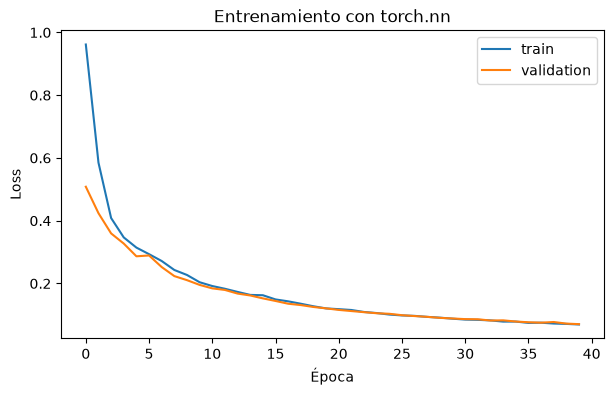

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(train_history_nn, label="train")
plt.plot(val_history_nn, label="validation")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Entrenamiento con torch.nn")
plt.legend()
plt.show()

In [25]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        logits = model(xb)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()

        correct += (preds == yb).sum().item()
        total += yb.numel()

print("Test accuracy:", correct / total)

Test accuracy: 1.0


# 11. Visualizar la frontera aprendida

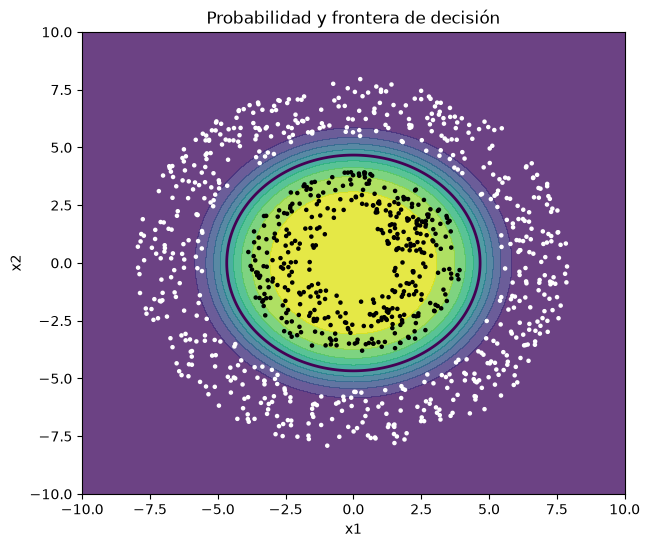

In [26]:
grid_x1, grid_x2 = torch.meshgrid(
    torch.linspace(-10, 10, 250),
    torch.linspace(-10, 10, 250),
    indexing="ij"
)

grid = torch.stack([grid_x1.reshape(-1), grid_x2.reshape(-1)], dim=1).to(device)

model.eval()
with torch.no_grad():
    grid_prob = torch.sigmoid(model(grid)).cpu().reshape(250, 250)

plt.figure(figsize=(7, 6))
plt.contourf(
    grid_x1.numpy(),
    grid_x2.numpy(),
    grid_prob.numpy(),
    levels=10,
    alpha=0.8,
    cmap="viridis"
)
plt.scatter(X[:, 0], X[:, 1], c=y, s=5, cmap="Grays")
plt.contour(
    grid_x1.numpy(),
    grid_x2.numpy(),
    grid_prob.numpy(),
    levels=[0.5],
    linewidths=2
)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Probabilidad y frontera de decisión")
plt.show()

# 12. Funciones de activación en PyTorch

PyTorch ofrece funciones de activación tanto como módulos (`nn.ReLU`) como en forma funcional (`torch.nn.functional.relu`).

Algunas de las principales:

- `nn.ReLU`
- `nn.LeakyReLU`
- `nn.ELU`
- `nn.GELU`
- `nn.SiLU`
- `nn.Tanh`
- `nn.Sigmoid`
- `nn.Softmax`

Para clasificación binaria con `BCEWithLogitsLoss` **no añadimos `Sigmoid` dentro del modelo durante el entrenamiento**, porque la loss trabaja directamente con logits.

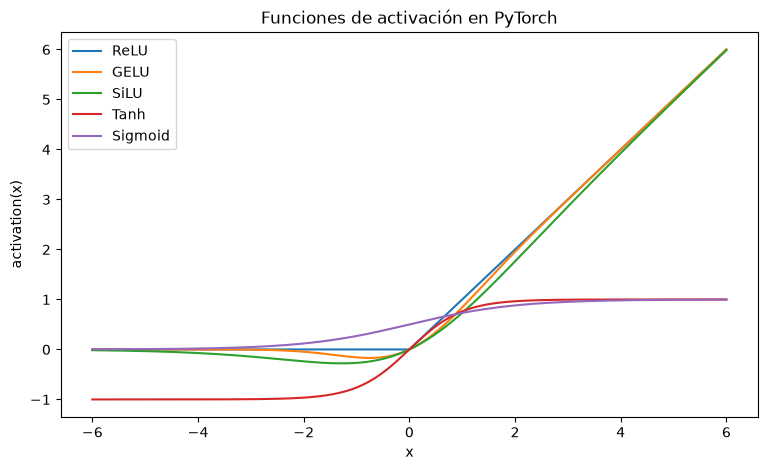

In [27]:
activation_x = torch.linspace(-6, 6, 300)

activation_values = {
    "ReLU": F.relu(activation_x),
    "GELU": F.gelu(activation_x),
    "SiLU": F.silu(activation_x),
    "Tanh": torch.tanh(activation_x),
    "Sigmoid": torch.sigmoid(activation_x),
}

plt.figure(figsize=(9, 5))
for name, values in activation_values.items():
    plt.plot(activation_x.numpy(), values.numpy(), label=name)

plt.xlabel("x")
plt.ylabel("activation(x)")
plt.title("Funciones de activación en PyTorch")
plt.legend()
plt.show()

# 13. Personalización de capas con `nn.Module`

En PyTorch, una capa personalizada también hereda de `nn.Module`.

Vamos a encapsular la transformación:

```python
x -> x²
```

en una capa independiente.

In [28]:
class SquareLayer(nn.Module):
    def forward(self, x):
        return x**2 

square = SquareLayer()
print(square(torch.tensor([[2.0, -3.0]])))

tensor([[4., 9.]])


Una capa también puede contener parámetros entrenables. Para registrarlos correctamente usamos `nn.Parameter`.

In [29]:
class ScaleLayer(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.scale = nn.Parameter(torch.ones(n_features))

    def forward(self, x):
        return x * self.scale

scale_layer = ScaleLayer(2)
print(scale_layer)
print(list(scale_layer.parameters()))

ScaleLayer()
[Parameter containing:
tensor([1., 1.], requires_grad=True)]


### Crear una capa densa usando clases

In [30]:
class MyDense(nn.Module):
    def __init__(self, in_features, out_features, activation=None):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.activation = activation  # string: "relu", "sigmoid", None...
        
        # En PyTorch los pesos se crean en __init__ (no hay build())
        self.weight = nn.Parameter(torch.empty(in_features, out_features))
        self.bias = nn.Parameter(torch.zeros(out_features))
        
        # Inicialización estilo glorot_uniform (Xavier)
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        z = x @ self.weight + self.bias  # equivalente a tf.matmul + bias
        if self.activation is not None:
            z = self._apply_activation(z)
        return z

    def _apply_activation(self, z):
        if self.activation == "relu":
            return F.relu(z)
        elif self.activation == "sigmoid":
            return torch.sigmoid(z)
        else:
            raise ValueError(f"Activación no soportada: {self.activation}")

In [31]:
x = torch.ones(4, 3)
print(x)
dense = MyDense(in_features=3, out_features=2, activation="relu")
y = dense(x)
y

tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])


tensor([[1.4623, 0.4543],
        [1.4623, 0.4543],
        [1.4623, 0.4543],
        [1.4623, 0.4543]], grad_fn=<ReluBackward0>)

### Ahora construyamos una capa de Dropout

In [32]:
class CustomDropout(nn.Module):
    def __init__(self, rate=0.5):
        super().__init__()
        assert 0 <= rate < 1, "rate debe estar en [0, 1)"
        self.rate = rate

    def forward(self, x):
        # En PyTorch, self.training lo gestiona automáticamente:
        #   model.train()  -> self.training = True
        #   model.eval()   -> self.training = False
        if not self.training:
            return x
        
        keep_prob = 1.0 - self.rate
        mask = (torch.rand_like(x) < keep_prob).to(x.dtype)
        return x * mask / keep_prob

In [33]:
dropout = CustomDropout(rate=0.5)

In [47]:
dropout.train()  # activa self.training = True
y_train = dropout(x)
print(y_train)

tensor([[2., 2., 0.],
        [0., 2., 2.],
        [2., 0., 2.],
        [0., 2., 0.]])


In [52]:
dropout.eval()  # self.training = False
y_eval = dropout(x)
print("\nEn modo eval (dropout desactivado):")
print(y_eval)


En modo eval (dropout desactivado):
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])


# 14. Modelo personalizado combinando capas

Ahora separamos explícitamente:

1. transformación no lineal;
2. clasificador lineal.

In [53]:
class CustomCircleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = SquareLayer()
        self.classifier = nn.Linear(2, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x.squeeze(1)

custom_model = CustomCircleClassifier().to(device)
print(custom_model)

CustomCircleClassifier(
  (features): SquareLayer()
  (classifier): Linear(in_features=2, out_features=1, bias=True)
)


### Usando las capas personalizadas


In [58]:
class MiModelo(nn.Module):
    def __init__(self, in_features=784, hidden=128, num_classes=10, dropout_rate=0.3):
        super().__init__()
        self.dense1 = MyDense(in_features, hidden, activation="relu")
        self.dropout = CustomDropout(dropout_rate)
        self.out = MyDense(hidden, num_classes, activation="sigmoid")

    def forward(self, x):
        x = self.dense1(x)
        x = self.dropout(x)
        x = self.out(x)
        return x


# ---------- Instancia ----------
device = "cuda" if torch.cuda.is_available() else "cpu"
model = MiModelo(in_features=3, hidden=2, num_classes=1, dropout_rate=0.3).to(device)
print(model)
y = model(x)
print(y.shape)

MiModelo(
  (dense1): MyDense()
  (dropout): CustomDropout()
  (out): MyDense()
)
torch.Size([4, 1])


In [59]:
x.shape

torch.Size([4, 3])

# 15. MLP: permitir que la red aprenda la no linealidad

Hasta ahora le dimos al modelo la transformación \(x^2\).

También podemos usar una red multicapa y dejar que aprenda una frontera no lineal a partir de las coordenadas originales.

In [60]:
class MLPClassifier(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

mlp = MLPClassifier(hidden=32).to(device)
print(mlp)

MLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [61]:
mlp_criterion = nn.BCEWithLogitsLoss()
mlp_optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)

for epoch in range(30):
    mlp.train()

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        mlp_optimizer.zero_grad()
        logits = mlp(xb)
        loss = mlp_criterion(logits, yb)
        loss.backward()
        mlp_optimizer.step()

    if epoch % 5 == 0:
        print(f"Epoch {epoch+1:2d} | loss={loss.item():.4f}")

Epoch  1 | loss=0.5420
Epoch  6 | loss=0.4687
Epoch 11 | loss=0.2159
Epoch 16 | loss=0.0808
Epoch 21 | loss=0.0485
Epoch 26 | loss=0.0295


In [62]:
mlp.eval()
correct = 0
total = 0

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        preds = (torch.sigmoid(mlp(xb)) >= 0.5).float()

        correct += (preds == yb).sum().item()
        total += yb.numel()

print("MLP test accuracy:", correct / total)

MLP test accuracy: 1.0


# 16. Relación entre implementación manual y `torch.nn`

| Concepto | PyTorch manual | `torch.nn` |
|---|---|---|
| Parámetros | tensor con `requires_grad=True` | `nn.Parameter` dentro de módulos |
| Forward | función Python | `forward()` |
| Gradientes | `loss.backward()` | `loss.backward()` |
| Reset gradientes | `tensor.grad.zero_()` | `optimizer.zero_grad()` |
| Actualización | operación manual | `optimizer.step()` |
| Loss | función manual/functional | `nn.BCEWithLogitsLoss()` |
| Batches | loops propios | `DataLoader` |
| Arquitectura | variables sueltas | `nn.Module` |

A diferencia de Keras, PyTorch mantiene normalmente un loop de entrenamiento explícito, aunque la gestión de parámetros queda organizada en `nn.Module`.

# 16. `train()` y `eval()`

Estas instrucciones **no entrenan** ni evalúan por sí mismas.

Cambian el comportamiento de capas que dependen del modo del modelo, por ejemplo:

- `Dropout`;
- `BatchNorm`.

```python
model.train()   # modo entrenamiento
model.eval()    # modo evaluación
```

Para desactivar además el cálculo de gradientes durante inferencia se usa:

```python
with torch.no_grad():
    ...
```

# Equivalencia conceptual con `compile()` de Keras

PyTorch no requiere un método `compile()` para definir la loss y el optimizador.

Normalmente se declaran explícitamente:

In [63]:
model_compile_equivalent = MLPClassifier(hidden=32).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model_compile_equivalent.parameters(),
    lr=1e-3
)

print(model_compile_equivalent)
print(criterion)
print(optimizer)

MLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
BCEWithLogitsLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


# 17. Equivalencia conceptual con `fit()`

PyTorch mantiene normalmente explícito el loop de entrenamiento.

Esto permite ver con claridad los pasos:

1. `model.train()`
2. cargar batch;
3. `optimizer.zero_grad()`
4. forward;
5. calcular loss;
6. `loss.backward()`
7. `optimizer.step()`
8. registrar métricas.

In [64]:
def fit_torch(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    history = {
        "loss": [],
        "val_loss": [],
        "accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        # -----------------------
        # Entrenamiento
        # -----------------------
        model.train()

        train_loss_sum = 0.0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * yb.size(0)

            preds = (torch.sigmoid(logits) >= 0.5).float()
            train_correct += (preds == yb).sum().item()
            train_total += yb.numel()

        train_loss = train_loss_sum / train_total
        train_accuracy = train_correct / train_total

        # -----------------------
        # Validación
        # -----------------------
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)

                val_loss_sum += loss.item() * yb.size(0)

                preds = (torch.sigmoid(logits) >= 0.5).float()
                val_correct += (preds == yb).sum().item()
                val_total += yb.numel()

        val_loss = val_loss_sum / val_total
        val_accuracy = val_correct / val_total

        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Epoch {epoch+1:02d} | "
            f"loss={train_loss:.4f} | acc={train_accuracy:.4f} | "
            f"val_loss={val_loss:.4f} | val_acc={val_accuracy:.4f}"
        )

    return history

In [65]:
history_torch = fit_torch(
    model_compile_equivalent,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10
)

Epoch 01 | loss=0.6486 | acc=0.5663 | val_loss=0.5858 | val_acc=0.6300
Epoch 02 | loss=0.5680 | acc=0.5988 | val_loss=0.5412 | val_acc=0.6300
Epoch 03 | loss=0.5424 | acc=0.5988 | val_loss=0.5170 | val_acc=0.6300
Epoch 04 | loss=0.5241 | acc=0.5988 | val_loss=0.4969 | val_acc=0.6300
Epoch 05 | loss=0.5046 | acc=0.6012 | val_loss=0.4800 | val_acc=0.6500
Epoch 06 | loss=0.4829 | acc=0.6275 | val_loss=0.4588 | val_acc=0.6600
Epoch 07 | loss=0.4555 | acc=0.6600 | val_loss=0.4276 | val_acc=0.7000
Epoch 08 | loss=0.4227 | acc=0.7350 | val_loss=0.3928 | val_acc=0.7500
Epoch 09 | loss=0.3848 | acc=0.8237 | val_loss=0.3552 | val_acc=0.8100
Epoch 10 | loss=0.3445 | acc=0.8525 | val_loss=0.3164 | val_acc=0.8700


# 18. `History` en PyTorch

PyTorch no crea automáticamente un objeto `History` como Keras.

Una práctica sencilla es almacenar las métricas en un diccionario.

dict_keys(['loss', 'val_loss', 'accuracy', 'val_accuracy'])


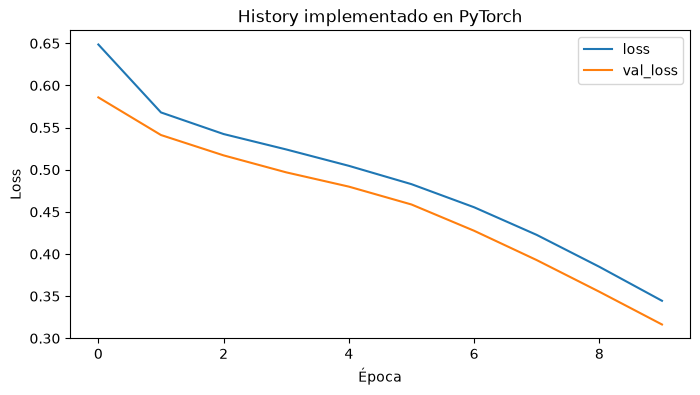

In [66]:
print(history_torch.keys())

plt.figure(figsize=(8, 4))
plt.plot(history_torch["loss"], label="loss")
plt.plot(history_torch["val_loss"], label="val_loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("History implementado en PyTorch")
plt.legend()
plt.show()

# 19. Equivalente de `evaluate()`

Creamos una función que:

- activa `model.eval()`;
- desactiva gradientes;
- calcula loss;
- calcula métricas.

In [67]:
def evaluate_torch(model, loader, criterion, threshold=0.5):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            probs = torch.sigmoid(logits)
            preds = (probs >= threshold).float()

            total_loss += loss.item() * yb.size(0)
            correct += (preds == yb).sum().item()
            total += yb.numel()

    return {
        "loss": total_loss / total,
        "accuracy": correct / total
    }

test_metrics = evaluate_torch(
    model_compile_equivalent,
    test_loader,
    criterion
)

print(test_metrics)

{'loss': 0.32379947423934935, 'accuracy': 0.85}


# 20. Equivalente de `predict()`

Una función de inferencia devuelve logits, probabilidades o clases.

In [68]:
def predict_torch(model, x, threshold=0.5):
    model.eval()

    with torch.no_grad():
        x = x.to(device)

        logits = model(x)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).long()

    return {
        "logits": logits.cpu(),
        "probabilities": probabilities.cpu(),
        "predictions": predictions.cpu()
    }

sample_x, _ = next(iter(test_loader))
prediction_output = predict_torch(
    model_compile_equivalent,
    sample_x[:5]
)

prediction_output

{'logits': tensor([-0.0683,  0.9314, -2.4670,  0.5672, -0.0435]),
 'probabilities': tensor([0.4829, 0.7174, 0.0782, 0.6381, 0.4891]),
 'predictions': tensor([0, 1, 0, 1, 0])}

# 21. Callbacks: patrón equivalente en PyTorch

PyTorch no impone una API nativa de callbacks para loops personalizados, pero podemos implementar hooks sencillos.

Por ejemplo, un callback puede recibir información al final de cada época.

class Callback: \
    def on_train_begin(self, logs=None, model=None, optimizer=None): \
        pass 

    def on_epoch_begin(self, epoch, logs=None, model=None, optimizer=None): 
        pass 

    def on_epoch_end(self, epoch, logs, model, optimizer): 
        pass 

    def on_train_end(self, logs=None, model=None, optimizer=None): 
        pass 

In [69]:
class Callback:
    def on_epoch_end(self, epoch, logs, model, optimizer):
        pass


class PrintLearningRate(Callback):
    def on_epoch_end(self, epoch, logs, model, optimizer):
        lr = optimizer.param_groups[0]["lr"]
        print(
            f"[callback] epoch={epoch+1:02d} "
            f"lr={lr:.6f} val_loss={logs['val_loss']:.4f}"
        )


class ModelCheckpoint(Callback):
    def __init__(self, filepath="best_model.pt"):
        self.filepath = filepath
        self.best = float("inf")

    def on_epoch_end(self, epoch, logs, model, optimizer):
        current = logs["val_loss"]

        if current < self.best:
            self.best = current

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": current
            }, self.filepath)

            print(f"[callback] checkpoint -> {self.filepath}")

In [70]:
def fit_torch_with_callbacks(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=10,
    callbacks=None
):
    callbacks = callbacks or []

    history = {
        "loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        val_metrics = evaluate_torch(model, val_loader, criterion)

        logs = {
            "loss": float(np.mean(train_losses)),
            "val_loss": val_metrics["loss"]
        }

        history["loss"].append(logs["loss"])
        history["val_loss"].append(logs["val_loss"])

        for callback in callbacks:
            callback.on_epoch_end(
                epoch,
                logs,
                model,
                optimizer
            )

    return history

In [71]:
callback_model = MLPClassifier(hidden=32).to(device)
callback_optimizer = torch.optim.Adam(
    callback_model.parameters(),
    lr=1e-3
)

callbacks = [
    PrintLearningRate(),
    ModelCheckpoint("best_classifier.pt")
]

callback_history = fit_torch_with_callbacks(
    callback_model,
    train_loader,
    val_loader,
    nn.BCEWithLogitsLoss(),
    callback_optimizer,
    epochs=5,
    callbacks=callbacks
)

[callback] epoch=01 lr=0.001000 val_loss=0.6334
[callback] checkpoint -> best_classifier.pt
[callback] epoch=02 lr=0.001000 val_loss=0.5661
[callback] checkpoint -> best_classifier.pt
[callback] epoch=03 lr=0.001000 val_loss=0.5348
[callback] checkpoint -> best_classifier.pt
[callback] epoch=04 lr=0.001000 val_loss=0.5083
[callback] checkpoint -> best_classifier.pt
[callback] epoch=05 lr=0.001000 val_loss=0.4797
[callback] checkpoint -> best_classifier.pt


# 22. Guardar y cargar modelos en PyTorch

La práctica más habitual es guardar el `state_dict`.

In [72]:
torch.save(
    model_compile_equivalent.state_dict(),
    "classifier_state_dict.pt"
)

restored_model = MLPClassifier(hidden=32).to(device)

state_dict = torch.load(
    "classifier_state_dict.pt",
    map_location=device
)

restored_model.load_state_dict(state_dict)
restored_model.eval()

print(restored_model)

MLPClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## Guardar también el estado del optimizador

Esto permite continuar un entrenamiento conservando información interna del optimizador.

In [73]:
torch.save({
    "model_state_dict": model_compile_equivalent.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "history": history_torch
}, "training_checkpoint.pt")

In [74]:
checkpoint = torch.load(
    "training_checkpoint.pt",
    map_location=device
)

restored_model = MLPClassifier(hidden=32).to(device)
restored_model.load_state_dict(
    checkpoint["model_state_dict"]
)

restored_optimizer = torch.optim.Adam(
    restored_model.parameters(),
    lr=1e-3
)
restored_optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

restored_history = checkpoint["history"]

print(restored_history.keys())

dict_keys(['loss', 'val_loss', 'accuracy', 'val_accuracy'])


# 23. Regularización L2

En muchos optimizadores de PyTorch se puede indicar:

```python
weight_decay=...
```

Por ejemplo:

```python
torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
```

Esto añade penalización sobre los pesos durante la optimización.

In [75]:
l2_model = MLPClassifier(hidden=32).to(device)

l2_optimizer = torch.optim.Adam(
    l2_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print(l2_optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


# 24. Regularización L1

Para L1 normalmente añadimos explícitamente el término:

$
\lambda_1 \sum_i |w_i|
$

a la loss.

In [ ]:
def l1_penalty(model):
    penalty = torch.tensor(0.0, device=device)

    for parameter in model.parameters():
        penalty = penalty + parameter.abs().sum()

    return penalty


lambda_l1 = 1e-6

xb, yb = next(iter(train_loader))
xb = xb.to(device)
yb = yb.to(device)

logits = l2_model(xb)

base_loss = nn.BCEWithLogitsLoss()(logits, yb)
loss_with_l1 = base_loss + lambda_l1 * l1_penalty(l2_model)

print("Base loss:", base_loss.item())
print("Loss + L1:", loss_with_l1.item())

# 25. Combinar L1 y L2

Podemos utilizar:

- `weight_decay` para L2;
- un término añadido manualmente para L1.

In [ ]:
combined_model = MLPClassifier(hidden=32).to(device)

combined_optimizer = torch.optim.Adam(
    combined_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

lambda_l1 = 1e-6

# Dentro del loop:
#
# logits = combined_model(xb)
# loss = criterion(logits, yb)
# loss = loss + lambda_l1 * l1_penalty(combined_model)
# loss.backward()
# combined_optimizer.step()

# 26. Dropout

`nn.Dropout(p)` pone a cero una fracción `p` de las activaciones durante `model.train()`.

En `model.eval()` se desactiva automáticamente.

In [76]:
dropout = nn.Dropout(p=0.5)

sample = torch.ones(3, 8)

dropout.train()
print("train():")
print(dropout(sample))

dropout.eval()
print("\neval():")
print(dropout(sample))

train():
tensor([[2., 0., 0., 0., 0., 2., 0., 2.],
        [2., 0., 0., 2., 0., 2., 0., 2.],
        [2., 2., 0., 2., 0., 0., 2., 2.]])

eval():
tensor([[1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])


# 27. Batch Normalization

Para datos tabulares representados como `(batch, features)` se puede usar `nn.BatchNorm1d`.

La capa mantiene estadísticas móviles y su comportamiento cambia entre:

```python
model.train()
model.eval()
```

In [77]:
batch_norm_model = nn.Sequential(
    nn.Linear(2, 32, bias=False),
    nn.BatchNorm1d(32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

print(batch_norm_model)

Sequential(
  (0): Linear(in_features=2, out_features=32, bias=False)
  (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Linear(in_features=32, out_features=1, bias=True)
)


# 28. Layer Normalization

`nn.LayerNorm` normaliza cada ejemplo sobre sus características.

No depende de las estadísticas del resto del batch.

In [79]:
layer_norm = nn.LayerNorm(8)

sample = torch.randn(4, 8)
normalized = layer_norm(sample)

print("Shape:", normalized.shape)
print("Media aproximada por muestra:")
print(normalized.mean(dim=1))

Shape: torch.Size([4, 8])
Media aproximada por muestra:
tensor([ 2.9802e-08, -1.4901e-08, -1.4901e-08,  4.4703e-08],
       grad_fn=<MeanBackward1>)


# 29. Group Normalization

`nn.GroupNorm(num_groups, num_channels)` divide los canales en grupos.

Para demostrarlo usaremos un tensor con forma:

```text
N x C x L
```

donde `C` representa los canales.

In [80]:
group_norm = nn.GroupNorm(
    num_groups=4,
    num_channels=8
)

sample = torch.randn(3, 8, 20)
normalized = group_norm(sample)

print("Entrada:", sample.shape)
print("Salida:", normalized.shape)

Entrada: torch.Size([3, 8, 20])
Salida: torch.Size([3, 8, 20])


# 30. Comparación conceptual de normalizaciones

| Capa | Estadísticas utilizadas | Depende del batch |
|---|---|---|
| `BatchNorm1d/2d/3d` | por canal sobre muestras del batch | Sí durante entrenamiento |
| `LayerNorm` | sobre características de cada muestra | No |
| `GroupNorm` | sobre grupos de canales | No |

El eje de normalización debe elegirse de acuerdo con la estructura del tensor.

# 31. Modelo que combina activación, normalización y Dropout

In [81]:
class NormalizedClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 64, bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.GELU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)

normalized_model = NormalizedClassifier().to(device)
print(normalized_model)

NormalizedClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=False)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (6): GELU(approximate='none')
    (7): Linear(in_features=32, out_features=1, bias=True)
  )
)


# 32. PyTorch Lightning: una forma más sencilla de organizar entrenamiento

Con PyTorch puro escribimos explícitamente el loop de entrenamiento.

**PyTorch Lightning** mantiene PyTorch por debajo, pero organiza el código de una forma más parecida a una API de alto nivel:

```python
model = LitClassifier()
trainer = pl.Trainer(...)
trainer.fit(model, train_loader, val_loader)
```

No existe un `compile()` idéntico al de Keras. En Lightning, la configuración del entrenamiento se reparte principalmente entre:

- `training_step()`
- `validation_step()`
- `configure_optimizers()`

## Instalación

Si Lightning no está instalado:

```python
pip install lightning
```

Import recomendado:

```python
import lightning as L
```

In [82]:
# Si es necesario:
# !pip install lightning

import lightning as L

print("Lightning:", L.__version__)

Lightning: 2.6.6


# 36. Modelo Lightning

Un `LightningModule` combina:

- arquitectura;
- forward;
- loss;
- métricas;
- optimizador;
- pasos de train/validation/test/predict.

In [83]:
class LitClassifier(L.LightningModule):
    def __init__(self, learning_rate=1e-3):
        super().__init__()

        self.learning_rate = learning_rate

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

        self.loss_fn = nn.BCEWithLogitsLoss()

    def forward(self, x):
        return self.network(x).squeeze(1)

    def training_step(self, batch, batch_idx):
        x, y = batch

        logits = self(x)
        loss = self.loss_fn(logits, y)

        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()
        acc = (preds == y).float().mean()

        self.log("train_loss", loss, prog_bar=True, on_epoch=True)
        self.log("train_acc", acc, prog_bar=True, on_epoch=True)

        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch

        logits = self(x)
        loss = self.loss_fn(logits, y)

        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()
        acc = (preds == y).float().mean()

        self.log("val_loss", loss, prog_bar=True, on_epoch=True)
        self.log("val_acc", acc, prog_bar=True, on_epoch=True)

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.learning_rate
        )

## Correspondencia aproximada con Keras

| Keras | PyTorch Lightning |
|---|---|
| arquitectura | `__init__()` |
| `call()` | `forward()` |
| `loss=` | `training_step()` / `validation_step()` |
| `optimizer=` | `configure_optimizers()` |
| `metrics=` | `self.log(...)` |
| `fit()` | `Trainer.fit()` |

Por tanto, `configure_optimizers()` es la parte más parecida a la configuración del optimizador dentro de `compile()`.

# 37. `fit()` con Lightning

El objeto `Trainer` controla:

- épocas;
- `backward()`;
- `optimizer.step()`;
- CPU/GPU;
- validación;
- logging;
- callbacks;
- checkpoints.

In [84]:
lit_model = LitClassifier(
    learning_rate=1e-3
)

trainer = L.Trainer(
    max_epochs=10,
    accelerator="auto",
    devices=1,
    log_every_n_steps=10
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [86]:
trainer.fit(
    lit_model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:881: Checkpoint directory c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\clase2\lightning_logs\version_25\checkpoints exists and is not empty.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ network │ Sequential        │  1.2 K │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴─────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 1.2 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.2 K                                                                                                
Total estimated model params size (MB): 0.005                                                                      
Modules in train mode: 7                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=10` reached.


Con Lightning ya no escribimos manualmente en cada batch:

```python
optimizer.zero_grad()
loss.backward()
optimizer.step()
```

Lightning realiza esos pasos automáticamente.

# 38. `validate()` y `test()`

Añadimos un `test_step()` para evaluar el conjunto de test.

In [87]:
class LitClassifierWithTest(LitClassifier):

    def test_step(self, batch, batch_idx):
        x, y = batch

        logits = self(x)
        loss = self.loss_fn(logits, y)

        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).float()
        acc = (preds == y).float().mean()

        self.log("test_loss", loss, prog_bar=True)
        self.log("test_acc", acc, prog_bar=True)

In [88]:
lit_model_test = LitClassifierWithTest(
    learning_rate=1e-3
)

trainer_test = L.Trainer(
    max_epochs=5,
    accelerator="auto",
    devices=1
)

trainer_test.fit(
    lit_model_test,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

test_results = trainer_test.test(
    lit_model_test,
    dataloaders=test_loader
)

test_results

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ network │ Sequential        │  1.2 K │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴─────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 1.2 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.2 K                                                                                                
Total estimated model params size (MB): 0.005                                                                      
Modules in train mode: 7                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\lightning\pytorch\loops\fi
t_loop.py:321: The number of training batches (13) is smaller than the logging interval 
Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training 
epoch.

`Trainer.fit` stopped: `max_epochs=5` reached.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.6000000238418579     │
│         test_loss         │    0.48028409481048584    │
└───────────────────────────┴───────────────────────────┘

c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


[{'test_loss': 0.48028409481048584, 'test_acc': 0.6000000238418579}]

# 39. `predict()` con Lightning

Para predicción implementamos `predict_step()`.

In [89]:
class LitClassifierComplete(LitClassifierWithTest):

    def predict_step(self, batch, batch_idx, dataloader_idx=0):
        x, _ = batch

        logits = self(x)
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).long()

        return {
            "probabilities": probabilities,
            "predictions": predictions
        }

In [90]:
lit_complete = LitClassifierComplete(
    learning_rate=1e-3
)

trainer_complete = L.Trainer(
    max_epochs=5,
    accelerator="auto",
    devices=1
)

trainer_complete.fit(
    lit_complete,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

predictions = trainer_complete.predict(
    lit_complete,
    dataloaders=test_loader
)

print(predictions[0]["probabilities"][:5])
print(predictions[0]["predictions"][:5])

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ network │ Sequential        │  1.2 K │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴─────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 1.2 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.2 K                                                                                                
Total estimated model params size (MB): 0.005                                                                      
Modules in train mode: 7                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=5` reached.


Output()

c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


tensor([0.3914, 0.4396, 0.1674, 0.4168, 0.3209])
tensor([0, 0, 0, 0, 0])


# 40. Callbacks con Lightning

Lightning incluye callbacks listos para usar. Por ejemplo:

- `ModelCheckpoint`
- `LearningRateMonitor`

In [91]:
from lightning.pytorch.callbacks import (
    ModelCheckpoint,
    LearningRateMonitor
)

checkpoint_callback = ModelCheckpoint(
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    filename="best-lightning-model"
)

lr_monitor = LearningRateMonitor(
    logging_interval="epoch"
)

trainer_callbacks = L.Trainer(
    max_epochs=10,
    accelerator="auto",
    devices=1,
    callbacks=[
        checkpoint_callback,
        lr_monitor
    ]
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [92]:
model_with_callbacks = LitClassifier(
    learning_rate=1e-3
)

trainer_callbacks.fit(
    model_with_callbacks,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

print(
    "Mejor checkpoint:",
    checkpoint_callback.best_model_path
)

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ network │ Sequential        │  1.2 K │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴─────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 1.2 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.2 K                                                                                                
Total estimated model params size (MB): 0.005                                                                      
Modules in train mode: 7                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=10` reached.


Mejor checkpoint: c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\clase2\lightning_logs\version_28\checkpoints\best-lightning-model.ckpt


# 41. Guardar y cargar modelos Lightning

Lightning puede guardar checkpoints completos.

In [93]:
trainer_callbacks.save_checkpoint(
    "classifier_lightning.ckpt"
)

loaded_lightning_model = LitClassifier.load_from_checkpoint(
    "classifier_lightning.ckpt",
    learning_rate=1e-3
)

loaded_lightning_model.eval()

`weights_only` was not set, defaulting to `False`.


LitClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
  (loss_fn): BCEWithLogitsLoss()
)

In [94]:
resultados = trainer.validate(loaded_lightning_model, dataloaders=val_loader)
print(resultados)

Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          val_acc          │    0.8700000047683716     │
│         val_loss          │    0.3289543092250824     │
└───────────────────────────┴───────────────────────────┘

[{'val_loss': 0.3289543092250824, 'val_acc': 0.8700000047683716}]


# 42. Keras vs PyTorch vs PyTorch Lightning

| Operación | Keras | PyTorch | PyTorch Lightning |
|---|---|---|---|
| Modelo | `Model` | `nn.Module` | `LightningModule` |
| Forward | `call()` | `forward()` | `forward()` |
| Configurar loss | `compile(loss=...)` | variable/función | `training_step()` |
| Configurar optimizer | `compile(optimizer=...)` | crear optimizer | `configure_optimizers()` |
| Entrenar | `fit()` | loop manual | `Trainer.fit()` |
| Evaluar | `evaluate()` | función propia | `Trainer.test()` / `Trainer.validate()` |
| Predicción | `predict()` | función propia | `Trainer.predict()` |
| Métricas | `metrics=` | código propio | `self.log()` |
| Callbacks | `callbacks=` | código propio | `callbacks=` |
| Checkpoints | `ModelCheckpoint` | `torch.save()` | `ModelCheckpoint` |

**PyTorch puro** tenemos `forward → loss → backward → optimizer.step()`, y después Lightning se encapsulan en una API más compacta.

In [1]:
# IMPORTANTE:
# definir el backend antes de importar keras

import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras import layers
import torch
import numpy as np
import matplotlib.pyplot as plt

print("Keras:", keras.__version__)
print("PyTorch:", torch.__version__)
print("Backend:", keras.backend.backend())

Keras: 3.15.1
PyTorch: 2.14.0+cpu
Backend: torch


In [2]:
model = keras.Sequential([
    keras.Input(shape=(2,)),

    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),

    layers.Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss=keras.losses.BinaryCrossentropy(
        from_logits=True
    ),

    metrics=[
        keras.metrics.BinaryAccuracy(
            name="accuracy",
            threshold=0.0
        )
    ]
)

In [8]:
history = model.fit(
    train_loader,
    validation_data=val_loader,
    epochs=20
)

Epoch 1/20
11/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5369 - loss: 0.7494

c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a torch DataLoader. The DataLoader is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5325 - loss: 0.7399 - val_accuracy: 0.5400 - val_loss: 0.6409
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5688 - loss: 0.5982 - val_accuracy: 0.6100 - val_loss: 0.5754
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6025 - loss: 0.5597 - val_accuracy: 0.6100 - val_loss: 0.5524
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6025 - loss: 0.5431 - val_accuracy: 0.6100 - val_loss: 0.5400
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6025 - loss: 0.5335 - val_accuracy: 0.6100 - val_loss: 0.5297
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6025 - loss: 0.5250 - val_accuracy: 0.6100 - val_loss: 0.5203
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6025 - loss: 0.5162 - val_accuracy: 0.6100 - val_loss: 0.5118
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6025 - loss: 0.5073 - val_accuracy: 0.6100 - val_loss: 0.5038
Ep

In [9]:
results = model.evaluate(
    test_loader,
    return_dict=True
)

print(results)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9600 - loss: 0.2282
{'accuracy': 0.9599999785423279, 'loss': 0.22816863656044006}


#### Personalizacion???

In [10]:
class SquareLayer(nn.Module):
    def forward(self, x):
        return x ** 2

square = SquareLayer()
print(square(torch.tensor([[2.0, -3.0]])))

tensor([[4., 9.]])


In [11]:
class CircleClassifierKeras(keras.Model):

    def __init__(self):
        super().__init__()

        self.square = SquareLayer()

        self.classifier = layers.Dense(1)

    def call(self, inputs):

        x = self.square(inputs)

        logits = self.classifier(x)

        return logits

In [12]:
custom_model = CircleClassifierKeras()

custom_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-2
    ),

    loss=keras.losses.BinaryCrossentropy(
        from_logits=True
    ),

    metrics=[
        keras.metrics.BinaryAccuracy(
            threshold=0.0,
            name="accuracy"
        )
    ]
)

In [13]:
history = custom_model.fit(
    train_loader,
    validation_data=val_loader,
    epochs=20
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4500 - loss: 16.6992 - val_accuracy: 0.4300 - val_loss: 16.6851
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4500 - loss: 14.2404 - val_accuracy: 0.4700 - val_loss: 14.1118
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4525 - loss: 12.0148 - val_accuracy: 0.5100 - val_loss: 11.9651
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4525 - loss: 10.1557 - val_accuracy: 0.5100 - val_loss: 10.0095
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4563 - loss: 8.4316 - val_accuracy: 0.5200 - val_loss: 8.2879
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4725 - loss: 6.9731 - val_accuracy: 0.5200 - val_loss: 6.7113
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4812 - loss: 5.6688 - val_accuracy: 0.5200 - val_loss: 5.3170
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4787 - loss: 4.5186 - val_accuracy: 0.5200 - 

In [15]:
results = custom_model.evaluate(
    test_loader,
    return_dict=True
)

print(results)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8600 - loss: 0.3246
{'accuracy': 0.8600000143051147, 'loss': 0.3246220350265503}


In [16]:
X_batch, y_batch = next(iter(train_loader))

output = custom_model(X_batch)

print(type(X_batch))
print(type(y_batch))
print(type(output))

print(X_batch.shape)
print(y_batch.shape)
print(output.shape)

<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>
torch.Size([64, 2])
torch.Size([64])
torch.Size([64, 1])
